# Geografische heatmaps van België — 2024

Vier kaarten op een vast raster van 2 × 2 km in Lambert 72 (EPSG:31370): alle letselongevallen, ernstige ongevallen, ongevallen met een voetganger en het ernstaandeel bij voldoende observaties. Alleen bruikbare coördinaten worden geplot. Rasteraantallen zijn geen risico per rit of per kilometer.

In [1]:
from pathlib import Path
import pandas as pd,geopandas as gpd,matplotlib.pyplot as plt
from shapely.geometry import box
from matplotlib.colors import LogNorm,Normalize
from matplotlib.cm import ScalarMappable
from IPython.display import display
B=Path.cwd()
if not (B/'figures').exists():B=B/'analysis_notebooks'
F=B/'figures';T=B/'tables';G=B.parent/'data/gold'
d=pd.read_parquet(G/'accident_map/accident_map.parquet')
bad=set(pd.read_csv(T/'geo_uitgesloten.csv',usecols=['_record_id'])._record_id)
x=d[(d.analysis_year==2024)&~d._record_id.isin(bad)].copy()
country=gpd.read_file(B/'reference_data/belgium_2024.geojson').to_crs(31370)
assert len(x)==33830


## Vaste cellen en controles
De kaart gebruikt de bronklasse: ernstig bij doden, dodelijk gewonden of zwaargewonden. Voetgangerongevallen volgen het veld `TX_COLLISION_TYPE_NL`. De som over de rastercellen wordt met de bron vergeleken.

In [2]:
CELL=2000
x['gx']=(x.MS_X_COORD//CELL).astype(int);x['gy']=(x.MS_Y_COORD//CELL).astype(int)
x['ernstig']=x.CD_CLASS_ACCIDENTS.isin(['1','2','3']).astype(int)
x['voetganger']=x.TX_COLLISION_TYPE_NL.eq('Met een voetganger').astype(int)
grid=x.groupby(['gx','gy']).agg(ongevallen=('_record_id','count'),ernstig=('ernstig','sum'),voetganger=('voetganger','sum')).reset_index()
grid['ernst_pct']=100*grid.ernstig/grid.ongevallen
assert grid.ongevallen.sum()==len(x)
assert grid.ernstig.sum()==x.ernstig.sum()
assert grid.voetganger.sum()==x.voetganger.sum()
geom=[box(a*CELL,b*CELL,(a+1)*CELL,(b+1)*CELL) for a,b in zip(grid.gx,grid.gy)]
g=gpd.GeoDataFrame(grid,geometry=geom,crs=31370)
g=gpd.clip(g,country)
g.to_parquet(T/'heatmap_raster_2km_2024.parquet',index=False)
grid.to_csv(T/'heatmap_raster_2km_2024.csv',index=False)
display(pd.DataFrame({'categorie':['Alle ongevallen','Ernstig','Met een voetganger','Cellen met >=20 ongevallen'],'aantal':[len(x),int(x.ernstig.sum()),int(x.voetganger.sum()),int((grid.ongevallen>=20).sum())]}))


,categorie,aantal
0,Alle ongevallen,33830
1,Ernstig,3012
2,Met een voetganger,3400
3,Cellen met >=20 ongevallen,309


## Kaarten
De drie aantalskaarten gebruiken elk een eigen logaritmische kleurlegenda. Vergelijk hun kleuren niet rechtstreeks. De laatste kaart toont het aandeel ernstige ongevallen alleen waar de cel minstens 20 ongevallen bevat.

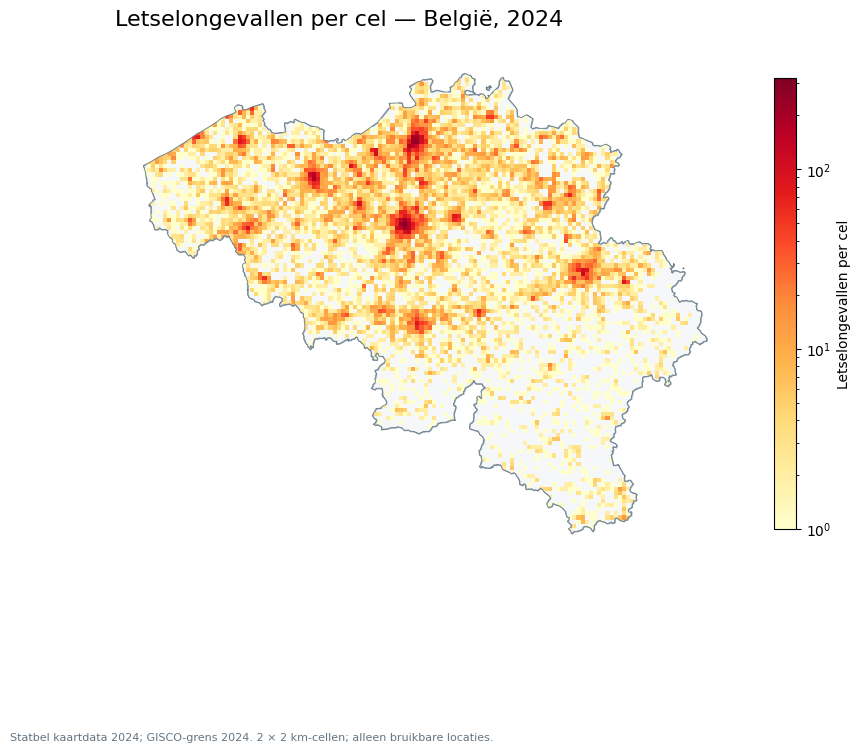

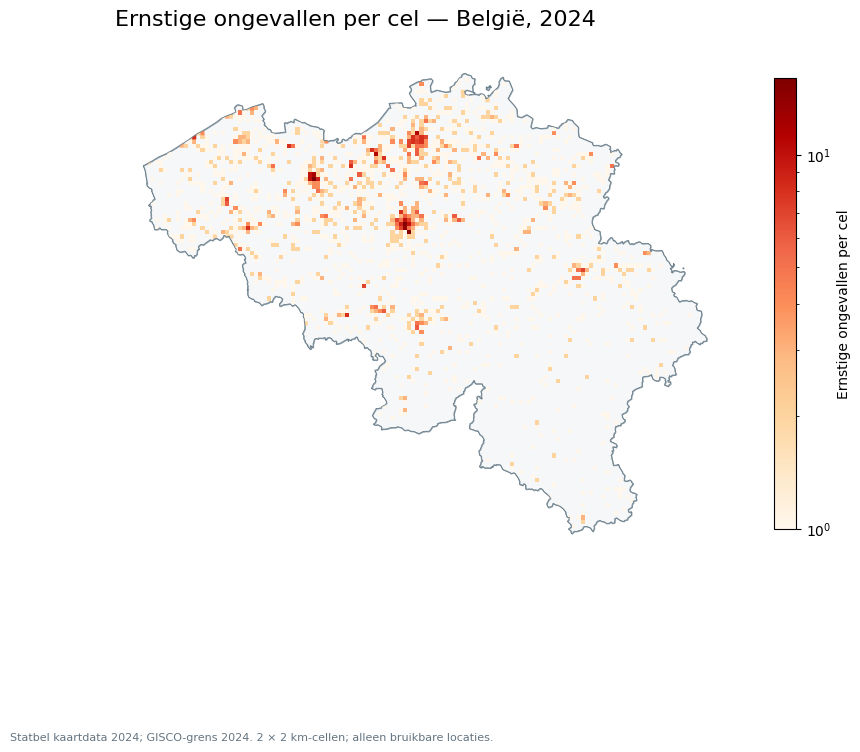

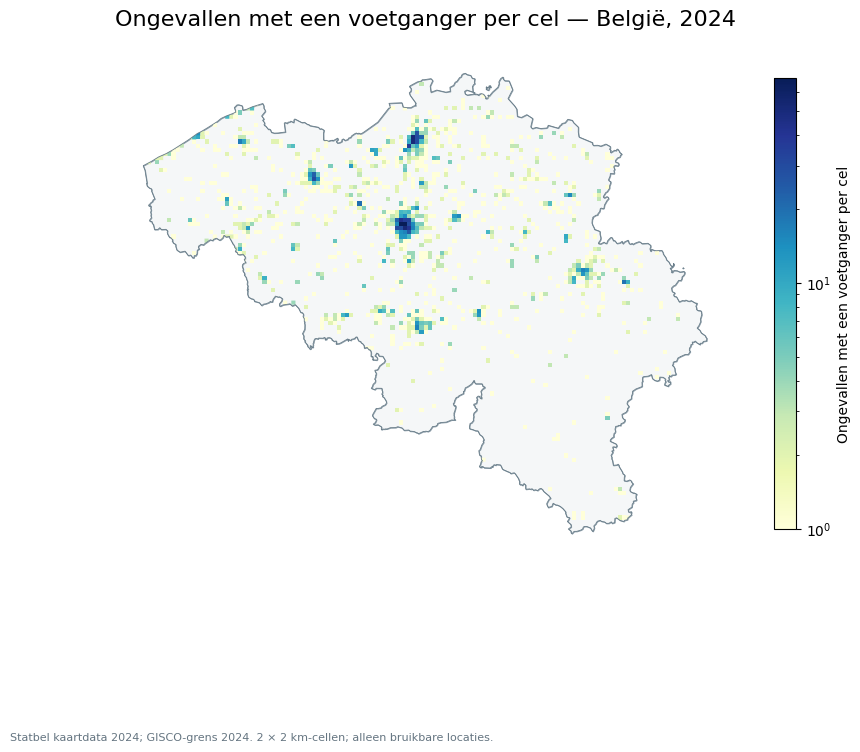

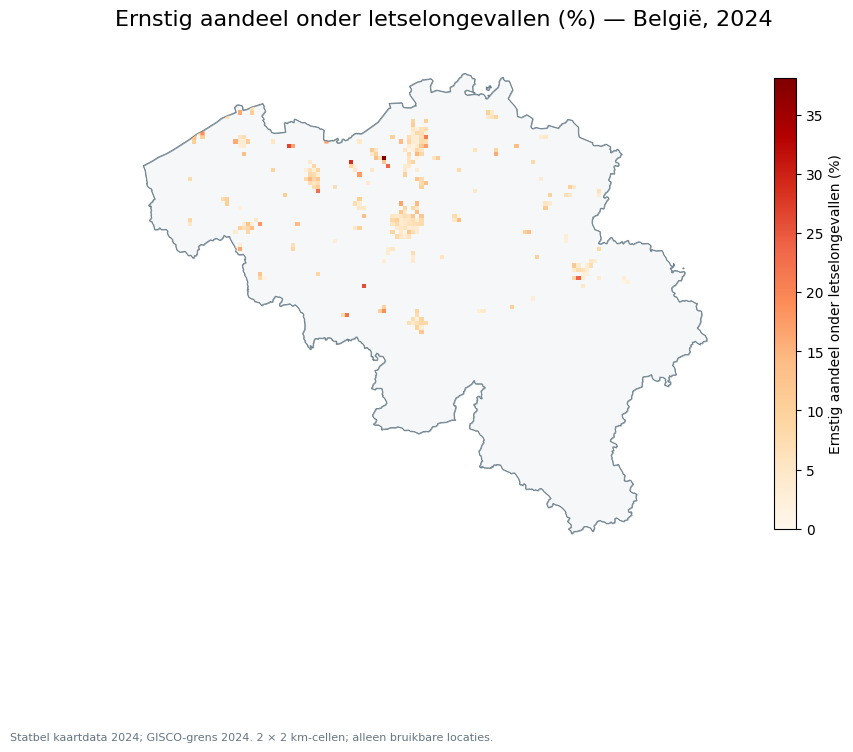

,gx,gy,ongevallen,ernstig,voetganger,ernst_pct
1081,52,96,184,16,29,8.7
2085,74,85,320,15,68,4.7
2145,75,83,126,15,25,11.9
2084,74,84,233,14,52,6.0
1082,52,97,159,12,23,7.5
2284,77,107,133,11,28,8.3
1698,67,102,112,11,10,9.8
2086,74,86,201,10,35,5.0
2147,75,85,165,10,29,6.1
1040,51,97,115,10,13,8.7


In [3]:
def heat(col,title,file,cmap='YlOrRd',minimum=None,log=True):
 z=g if minimum is None else g[g.ongevallen>=minimum]
 z=z[z[col]>0]
 fig,ax=plt.subplots(figsize=(10,9));country.plot(ax=ax,color='#F5F7F8',edgecolor='#8799A5',linewidth=.7)
 norm=LogNorm(vmin=1,vmax=max(2,z[col].max())) if log else Normalize(vmin=0,vmax=z[col].max())
 z.plot(ax=ax,column=col,cmap=cmap,norm=norm,edgecolor='none',linewidth=0)
 country.boundary.plot(ax=ax,color='#697D89',linewidth=.6)
 fig.colorbar(ScalarMappable(norm=norm,cmap=cmap),ax=ax,shrink=.65,label=title)
 ax.axis('off');ax.set_title(title+' — België, 2024',loc='left',fontsize=16,pad=18)
 fig.text(.02,.01,'Statbel kaartdata 2024; GISCO-grens 2024. 2 × 2 km-cellen; alleen bruikbare locaties.',fontsize=8,color='#657581')
 fig.savefig(F/(file+'.png'),dpi=200,bbox_inches='tight');fig.savefig(F/(file+'.svg'),bbox_inches='tight');plt.show();plt.close(fig)
heat('ongevallen','Letselongevallen per cel','22_heatmap_alle_ongevallen')
heat('ernstig','Ernstige ongevallen per cel','23_heatmap_ernstig','OrRd')
heat('voetganger','Ongevallen met een voetganger per cel','24_heatmap_voetganger','YlGnBu')
heat('ernst_pct','Ernstig aandeel onder letselongevallen (%)','25_heatmap_ernstaandeel','OrRd',20,False)
display(grid[grid.ongevallen>=20].sort_values(['ernstig','ongevallen'],ascending=False).head(15).round(1))


## Interpretatie
Gebruik de kaarten als startpunt voor locatieonderzoek. Drukke cellen kunnen een hogere blootstelling aan verkeer hebben; een hoge ernstfractie bij 20 ongevallen blijft onzeker. Bevestig locatie en wegsegment vóór een claim over een specifieke weg. Ongevallen zonder coördinaten ontbreken op deze kaarten; de dekking van 2024 is 94,2% van de kaartbron.